# E12-H63 - semantic threshold band fragility

**Author**: Konrad Jelen (kj)<br>
**Pipeline stage**: experiment - E12 hypothesis probe, verdict layer only

`DEFAULT_THRESHOLD = 0.77` (`src/docdistance/distance.py:30`) sits inside an in-sample band whose edges the
shipped provenance comment records as **min gold 79.7% (haiku)** and **max adversarial 75.0% (adv2-b)** on the
11 ibm-ai-adoption fixtures under the OpenVINO INT8 backend. Both edges are **sample extremes of n = 11**, the
highest-variance statistic the fixture can produce, and each is set by a single document. Independently, the
shipped INT8 artifact drifts at `emb_cos = 0.9939` against the fp backbone
(`reports/02-mmbert-quantization-metrics.json` `part_b_cpu_openvino_int8`), a perturbation on the same
$10^{-3}$ to $10^{-2}$ closeness scale as the band's own 2.7 / 2.0-point margins.

This notebook is a **probe**: it measures the band's fragility and publishes a sensitivity card. No threshold
changes, no code under `src/` is touched, and every number comes from the shipped functions.

## Approach

1. **Kill-gate first** - re-read the recorded band margins and the shipped backend `emb_cos`; the gate dies only
   if every margin exceeded 5 closeness points *and* `emb_cos` were exactly 1.0
2. **Provenance** - from notebook 09's recorded cell text alone, decide which generation of the fixture set
   the band and which computation produced it; report a corpus swap or a path mismatch as a named finding
3. **Arm 0 - shipped INT8 path** - score the 11 summaries against the gold anchor through `DocDistance()`;
   publish closeness, verdict and margin to 0.77 per document
4. **Arm 1 - fp backbone** - re-encode the *same* segmented statements with `TorchEncoder(device="cpu")`, so the
   only difference between the arms is the encoder numerics
5. **Leave-one-out** - recompute the band edges under all 11 leave-one-out subsets
6. **Threshold-flip curve** - sweep 0.70 to 0.85 at 0.005 and count verdict flips and tier errors per backend
7. **Guardrails** - `V` re-verified on both backends, default-path `smd` and `order_gap` bit-identity by
   `np.array_equal`, metric property (triangle inequality) counted, `DEFAULT_THRESHOLD` unchanged

## Outputs

- The per-document margin table, the leave-one-out edge table, the backend-drift column and the threshold-flip
  curve, each charted inline
- A provenance reconciliation of the recorded band against the shipped `semantic_distance` path
- A fragility card restating the safe band per backend in the terms of the `distance.py` provenance comment
- `reports/E12-H63-semantic-threshold-band-metrics.json`


## Environment

CPU only. The workstation GPUs are occupied by foreign jobs for the duration of this campaign, so
`CUDA_VISIBLE_DEVICES` is pinned empty before any torch import: the INT8 arm is the OpenVINO CPU path the
library ships, and the fp arm is `TorchEncoder(device="cpu")` in fp32. Wall-clock timings here are not
measurements - the 64-thread CPU is shared with the other executors of this campaign.

In [1]:
import os

os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = ""       # CPU pin: GPUs are held by foreign jobs; both arms are CPU
os.environ["HF_HUB_OFFLINE"] = "1"            # models are cached; the library never downloads here
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

ROOT_STR = "/home/lab/workspace/learning/projects/docdistance"
os.environ["DOCDISTANCE_HOME"] = ROOT_STR     # docdistance.json lives at the repo root, not the notebook cwd

import warnings
warnings.filterwarnings("ignore")

import torch
print(f"torch {torch.__version__} | cuda visible: {torch.cuda.is_available()} | arms: OpenVINO INT8 (CPU) + torch fp32 (CPU)")

torch 2.11.0+cu130 | cuda visible: False | arms: OpenVINO INT8 (CPU) + torch fp32 (CPU)


## Imports

In [2]:
import ast
import contextlib
import io
import json
import re
from itertools import combinations
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rich.console import Console
from rich.panel import Panel
from rich.table import Table

import docdistance
from docdistance import DocDistance
from docdistance.distance import DEFAULT_THRESHOLD, SMD_MAX, closeness, smd, verdict
from docdistance.encoders import TorchEncoder

console = Console()
sns.set_theme(style="whitegrid", context="notebook")
print(f"imports ready | docdistance {docdistance.__version__} | numpy {np.__version__}")

imports ready | docdistance 1.1.5 | numpy 2.4.6


## Reproducibility

Nothing here samples: every arm is a deterministic forward pass plus an exact network-simplex transport solve.
The seed is fixed anyway so any later addition inherits it.

In [3]:
SEED = 0
np.random.seed(SEED)
print(f"SEED={SEED}")

SEED=0


## Configuration

The live 11-summary ibm-ai-adoption fixture: one gold anchor, six further gold-tier summaries and four
adversarial summaries in two tiers. The anchor is the reference every distance is taken against, so ten
documents carry a closeness. `V` is the gold-versus-adversarial ordinality violation count over the
$6 \times 4 = 24$ tier pairs. The recorded band and the shipped backend fidelity are read from disk, never
retyped.

In [4]:
ROOT = Path(ROOT_STR)
SUMMARY_DIR = ROOT / "data/interim/exec-summaries/ibm-ai-adoption/summaries"
DISTANCE_PY = ROOT / "src/docdistance/distance.py"
QUANT_METRICS = ROOT / "reports/02-mmbert-quantization-metrics.json"
NB09 = ROOT / "notebooks/09-kj-docdistance-api-e2e.ipynb"
REPORT = ROOT / "reports/E12-H63-semantic-threshold-band-metrics.json"

DOCS = [
    ("exec-summary-gold-opus-4-6.md",     "gold",   "gold"),   # reference anchor
    ("exec-summary-gold-2-opus-4-6.md",   "gold-2", "gold"),
    ("exec-summary-1-opus-4-6.md",        "v1",     "gold"),
    ("exec-summary-2-opus-4-6.md",        "v2",     "gold"),
    ("exec-summary-opus-4-6.md",          "opus",   "gold"),
    ("exec-summary-sonnet-4-6.md",        "sonnet", "gold"),
    ("exec-summary-haiku-4-5.md",         "haiku",  "gold"),
    ("exec-summary-adv1-a-sonnet-4-6.md", "adv1-a", "adv1"),
    ("exec-summary-adv1-b-sonnet-4-6.md", "adv1-b", "adv1"),
    ("exec-summary-adv2-a-haiku-4-5.md",  "adv2-a", "adv2"),
    ("exec-summary-adv2-b-haiku-4-5.md",  "adv2-b", "adv2"),
]
REFERENCE = "gold"
tier_of = {lbl: t for _, lbl, t in DOCS}
file_of = {lbl: f for f, lbl, _ in DOCS}
SCORED = [lbl for _, lbl, _ in DOCS if lbl != REFERENCE]
GOLDS = [l for l in SCORED if tier_of[l] == "gold"]
ADVS = [l for l in SCORED if tier_of[l] != "gold"]
V_PAIRS = len(GOLDS) * len(ADVS)

TIER_COLOR = {"gold": "#2ca02c", "adv1": "#ff7f0e", "adv2": "#d62728"}
BACKEND_COLOR = {"int8": "#1f77b4", "fp": "#9467bd"}

# pre-registered bars (E12-H63)
GATE_MARGIN_PTS = 5.0        # kill-gate: every recorded margin above this AND emb_cos == 1.0 kills the claim
HALFWIDTH_BAR_PTS = 2.7      # prediction 1: band half-width stays at or below this
LOO_EDGE_BAR_PTS = 1.0       # prediction 2: dropping the edge document moves that edge by at least this
DRIFT_FRAC_BAR = 0.20        # prediction 3: some document's backend drift exceeds this fraction of its margin
SWEEP = np.round(np.arange(0.700, 0.8501, 0.005), 4)   # threshold-flip sweep, 0.70-0.85 at 0.005
TRI_TOL = 1e-9               # triangle-inequality slack for the metric-property check

# the recorded band, parsed out of the shipped provenance comment (never retyped)
prov = DISTANCE_PY.read_text(encoding="utf-8")
prov_flat = re.sub(r"\n#\s*", " ", prov)   # the provenance comment wraps across lines; join continuations
m_band = re.search(r"min gold ([\d.]+)% \((\w[\w-]*)\) vs max adversarial ([\d.]+)% \((\w[\w-]*)\)", prov_flat)
REC_MIN_GOLD, REC_MIN_GOLD_DOC, REC_MAX_ADV, REC_MAX_ADV_DOC = (
    float(m_band.group(1)), m_band.group(2), float(m_band.group(3)), m_band.group(4),
)
m_thr = re.search(r"^DEFAULT_THRESHOLD = ([\d.]+)", prov, re.M)
SHIPPED_THRESHOLD = float(m_thr.group(1))

QM = json.loads(QUANT_METRICS.read_text(encoding="utf-8"))
EMB_COS_SHIPPED = QM["part_b_cpu_openvino_int8"]["emb_cos"]
EMB_COS_SCHEME = [r for r in QM["part_a_scheme_comparison"] if r["smoothing"] == "SmoothQuant" and r["activations"] == "per_token"][0]["emb_cos"]

cfg = Table.grid(padding=(0, 2))
cfg.add_column(style="bold cyan"); cfg.add_column()
cfg.add_row("Fixture", f"{len(DOCS)} live summaries, anchor {file_of[REFERENCE]}")
cfg.add_row("Scored documents", f"{len(SCORED)} ({len(GOLDS)} gold, {len(ADVS)} adversarial)")
cfg.add_row("Ordinality pairs V", f"{V_PAIRS}")
cfg.add_row("Arms", "int8 = DocDistance() default (OpenVINO INT8, CPU); fp = TorchEncoder(device='cpu') fp32")
cfg.add_row("Shipped threshold", f"{SHIPPED_THRESHOLD} (distance.py DEFAULT_THRESHOLD)")
cfg.add_row("Recorded band", f"[{REC_MAX_ADV/100:.3f}, {REC_MIN_GOLD/100:.3f}] "
                             f"= max adv {REC_MAX_ADV}% ({REC_MAX_ADV_DOC}) .. min gold {REC_MIN_GOLD}% ({REC_MIN_GOLD_DOC})")
cfg.add_row("Shipped backend emb_cos", f"{EMB_COS_SHIPPED:.4f} (part_b; part_a scheme figure {EMB_COS_SCHEME:.4f})")
cfg.add_row("Threshold sweep", f"{SWEEP[0]:.3f} .. {SWEEP[-1]:.3f} step 0.005 ({len(SWEEP)} points)")
cfg.add_row("Metrics JSON", str(REPORT.relative_to(ROOT)))
console.print(Panel(cfg, title="E12-H63 configuration", border_style="cyan"))

╭───────────────────────────────────────────── E12-H63 configuration ─────────────────────────────────────────────╮
│ Fixture                  11 live summaries, anchor exec-summary-gold-opus-4-6.md                                │
│ Scored documents         10 (6 gold, 4 adversarial)                                                             │
│ Ordinality pairs V       24                                                                                     │
│ Arms                     int8 = DocDistance() default (OpenVINO INT8, CPU); fp = TorchEncoder(device='cpu')     │
│                          fp32                                                                                   │
│ Shipped threshold        0.77 (distance.py DEFAULT_THRESHOLD)                                                   │
│ Recorded band            [0.750, 0.797] = max adv 75.0% (adv2-b) .. min gold 79.7% (haiku)                      │
│ Shipped backend emb_cos  0.9939 (part_b; part_a scheme figure 0.9984)                                           │
│ Threshold sweep          0.700 .. 0.850 step 0.005 (31 points)                                                  │
│ Metrics JSON             reports/E12-H63-semantic-threshold-band-metrics.json                                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Kill-gate

The registered gate: **if the 11 closeness margins to 0.77 were all above 5 points and the backend `emb_cos`
were 1.0, the fragility claim dies.** It is evaluated on the recorded values before any model is loaded, so a
killed gate costs nothing. Both conditions must hold to kill; either one failing keeps the hypothesis alive.

In [5]:
rec_margin_min_gold = abs(REC_MIN_GOLD - SHIPPED_THRESHOLD * 100)
rec_margin_max_adv = abs(REC_MAX_ADV - SHIPPED_THRESHOLD * 100)
rec_margins = {REC_MIN_GOLD_DOC: rec_margin_min_gold, REC_MAX_ADV_DOC: rec_margin_max_adv}

all_margins_wide = all(v > GATE_MARGIN_PTS for v in rec_margins.values())
backend_exact = EMB_COS_SHIPPED == 1.0
GATE_KILLED = all_margins_wide and backend_exact

gt = Table(title="Kill-gate readings (recorded values, no model loaded)", header_style="bold cyan")
gt.add_column("condition"); gt.add_column("reading", justify="right"); gt.add_column("kills?", justify="center")
gt.add_row(f"every recorded margin to {SHIPPED_THRESHOLD} above {GATE_MARGIN_PTS} pts",
           " / ".join(f"{k} {v:.1f} pts" for k, v in rec_margins.items()),
           "[green]no[/green]" if not all_margins_wide else "[red]yes[/red]")
gt.add_row("shipped backend emb_cos exactly 1.0", f"{EMB_COS_SHIPPED:.4f}",
           "[green]no[/green]" if not backend_exact else "[red]yes[/red]")
console.print(gt)

GATE_READING = (f"recorded margins {REC_MIN_GOLD_DOC} {rec_margin_min_gold:.1f} pts and "
                f"{REC_MAX_ADV_DOC} {rec_margin_max_adv:.1f} pts, both at or below {GATE_MARGIN_PTS}; "
                f"shipped emb_cos {EMB_COS_SHIPPED:.4f} below 1.0")
console.print(Panel(f"[bold]{'KILLED' if GATE_KILLED else 'PASSED'}[/bold] - {GATE_READING}",
                    border_style="red" if GATE_KILLED else "green", title="kill-gate"))
assert not GATE_KILLED, "gate killed - the run stops here with the reading persisted"

                  Kill-gate readings (recorded values, no model loaded)                  
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃ condition                                   ┃                        reading ┃ kills? ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩
│ every recorded margin to 0.77 above 5.0 pts │ haiku 2.7 pts / adv2-b 2.0 pts │   no   │
│ shipped backend emb_cos exactly 1.0         │                         0.9939 │   no   │
└─────────────────────────────────────────────┴────────────────────────────────┴────────┘

╭─────────────────────────────────────────────────── kill-gate ───────────────────────────────────────────────────╮
│ PASSED - recorded margins haiku 2.7 pts and adv2-b 2.0 pts, both at or below 5.0; shipped emb_cos 0.9939 below  │
│ 1.0                                                                                                             │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Provenance - which corpus and which computation set the recorded band

Two provenance questions, both decided from **notebook 09's recorded cell text alone** - the archive directory
is never opened. First the corpus: if notebook 09 scored an archived earlier generation while the live corpus is
the opus-4-6 one, the band and the documents it is applied to come from different fixtures and the corpus swap
is itself the finding. Second the computation: the `distance.py` provenance comment attributes the band to
notebook 09 **cell 10**, which scores through `dd.embed` plus `smd`, while **cell 13** of the same notebook
scores three of the same documents through the shipped `semantic_distance` one-shot and reports different
numbers at the same library version. A band read off a path that is not the shipped path is a provenance
mismatch and is reported here, not absorbed into a version-drift story.

In [6]:
nb09 = json.loads(NB09.read_text(encoding="utf-8"))
nb09_code = "\n".join("".join(c["source"]) for c in nb09["cells"] if c["cell_type"] == "code")
nb09_files = sorted(set(re.findall(r"exec-summary-[\w.-]+\.md", nb09_code)))

ansi = re.compile(r"\x1b\[[0-9;]*m")
def _out_text(cell):
    """Recorded output text of a cell: stream text plus the text/plain of rich display output, ANSI stripped."""
    parts = []
    for o in cell.get("outputs", []):
        if "text" in o:
            parts.append("".join(o["text"]))
        elif "text/plain" in o.get("data", {}):
            parts.append("".join(o["data"]["text/plain"]))
    return ansi.sub("", "\n".join(parts))

def _cell_with(needle):
    """The notebook-09 code cell whose source contains `needle` - located by content, never by index."""
    return next(c for c in nb09["cells"] if c["cell_type"] == "code" and needle in "".join(c["source"]))

nb09_out = "\n".join(_out_text(c) for c in nb09["cells"])
m_rec = re.search(r"ordinality violations:\s*(\d+)\s*/\s*(\d+)\s*\(?\s*min gold\s*([\d.]+)%\s*vs max adversarial\s*([\d.]+)%",
                  nb09_out, re.S)
nb09_V, nb09_Vp, nb09_min_gold, nb09_max_adv = int(m_rec.group(1)), int(m_rec.group(2)), float(m_rec.group(3)), float(m_rec.group(4))

# --- corpus question -------------------------------------------------------------------------------
live_files = sorted(p.name for p in SUMMARY_DIR.glob("*.md"))   # top level only; @archive is never traversed
declared = sorted(file_of.values())
CORPUS_SWAP = sorted(nb09_files) != declared or live_files != declared

pt = Table(title="Corpus provenance of the recorded band", header_style="bold cyan")
pt.add_column("source"); pt.add_column("n"); pt.add_column("generation tags")
def _tags(names):
    return ", ".join(sorted({re.sub(r"^exec-summary-.*?-(\w+-[\d-]+)\.md$", r"\1", n) for n in names}))
pt.add_row("notebook 09 recorded cell text", str(len(nb09_files)), _tags(nb09_files))
pt.add_row("live summaries directory", str(len(live_files)), _tags(live_files))
pt.add_row("this notebook's DOCS", str(len(declared)), _tags(declared))
console.print(pt)

CORPUS_NOTE = ("no corpus swap: notebook 09's recorded cell text names the same 11 live opus-4-6 / sonnet-4-6 / "
               "haiku-4-5 filenames this notebook scores"
               if not CORPUS_SWAP else
               "CORPUS SWAP: notebook 09 scored a different filename set from the live corpus")
console.print(f"[bold]{CORPUS_NOTE}[/bold]")

# --- path question ---------------------------------------------------------------------------------
NB09_VERSION = _out_text(_cell_with('print("docdistance", docdistance.__version__)')).strip().split()[-1]
c10 = _cell_with("ordinality violations")        # the band cell: dd.embed + smd
c13 = _cell_with("DistanceResult.to_dict()")     # the shipped one-shot: semantic_distance

_row = re.compile(r"^\s*│\s*([\w][\w-]*)\s*│\s*(gold|adv1|adv2)\s*│\s*([\d.]+)\s*│\s*([\d.]+)%")
NB09_C10 = {}
for line in _out_text(c10).splitlines():
    m = _row.match(line)
    if m:
        NB09_C10[m.group(1)] = {"smd": float(m.group(3)), "closeness_pct": float(m.group(4))}

label_of = {f: l for l, f in file_of.items()}
_c13_out = _out_text(c13)
NB09_C13 = {}
for m in re.finditer(r"(exec-summary-[\w.-]+\.md)\s+SMD ([\d.]+)\s+closeness\s+([\d.]+)%", _c13_out):
    NB09_C13[label_of[m.group(1)]] = {"smd": float(m.group(2)), "closeness_pct": float(m.group(3))}
NB09_C13_TODICT = ast.literal_eval(re.search(r"DistanceResult\.to_dict\(\):\s*(\{.*?\})", _c13_out, re.S).group(1))
PATH_DOCS = [l for l in SCORED if l in NB09_C13]
PATH_MISMATCH = any(NB09_C10[l]["smd"] != NB09_C13[l]["smd"] for l in PATH_DOCS)

qt = Table(title=f"notebook 09 at docdistance {NB09_VERSION}: the band cell against the shipped one-shot",
           header_style="bold cyan")
for c, j in [("doc", "left"), ("cell 10 SMD (dd.embed + smd)", "right"),
             ("cell 13 SMD (semantic_distance)", "right"), ("cell 10 - cell 13", "right")]:
    qt.add_column(c, justify=j)
for l in PATH_DOCS:
    qt.add_row(l, f"{NB09_C10[l]['smd']:.4f}", f"{NB09_C13[l]['smd']:.4f}",
               f"{NB09_C10[l]['smd'] - NB09_C13[l]['smd']:+.4f}", style="yellow")
for l in (REC_MIN_GOLD_DOC, REC_MAX_ADV_DOC):
    qt.add_row(f"{l} (a band edge)", f"{NB09_C10[l]['smd']:.4f}", "not scored by cell 13", "-")
console.print(qt)

print(f"notebook 09 recorded readings (cell 10, docdistance {NB09_VERSION}): V {nb09_V}/{nb09_Vp}, "
      f"min gold {nb09_min_gold}%, max adversarial {nb09_max_adv}% - the values in the distance.py provenance comment")
print(f"path mismatch inside notebook 09 at one version: {PATH_MISMATCH} "
      f"({len(PATH_DOCS)} of 10 documents were scored by both cells, and cell 10 disagrees with the shipped "
      f"semantic_distance on every one of them)")
print(f"the two band edge documents ({REC_MIN_GOLD_DOC}, {REC_MAX_ADV_DOC}) were scored by cell 10 only, "
      f"so the recorded band has no shipped-path counterpart at {NB09_VERSION}")

                      Corpus provenance of the recorded band                       
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ source                         ┃ n  ┃ generation tags                           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ notebook 09 recorded cell text │ 11 │ 4-5, 4-6, haiku-4-5, opus-4-6, sonnet-4-6 │
│ live summaries directory       │ 11 │ 4-5, 4-6, haiku-4-5, opus-4-6, sonnet-4-6 │
│ this notebook's DOCS           │ 11 │ 4-5, 4-6, haiku-4-5, opus-4-6, sonnet-4-6 │
└────────────────────────────────┴────┴───────────────────────────────────────────┘

no corpus swap: notebook 09's recorded cell text names the same 11 live opus-4-6 / sonnet-4-6 / haiku-4-5 filenames
this notebook scores

                notebook 09 at docdistance 1.1.2: the band cell against the shipped one-shot                 
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ doc                  ┃ cell 10 SMD (dd.embed + smd) ┃ cell 13 SMD (semantic_distance) ┃ cell 10 - cell 13 ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ gold-2               │                       0.2258 │                          0.2265 │           -0.0007 │
│ adv1-a               │                       0.4579 │                          0.4569 │           +0.0010 │
│ adv2-a               │                       0.3811 │                          0.3806 │           +0.0005 │
│ haiku (a band edge)  │                       0.2870 │           not scored by cell 13 │                 - │
│ adv2-b (a band edge) │                       0.3543 │           not scored by cell 13 │                 - │
└──────────────────────┴──────────────────────────────┴─────────────────────────────────┴───────────────────┘

notebook 09 recorded readings (cell 10, docdistance 1.1.2): V 0/24, min gold 79.7%, max adversarial 75.0% - the values in the distance.py provenance comment
path mismatch inside notebook 09 at one version: True (3 of 10 documents were scored by both cells, and cell 10 disagrees with the shipped semantic_distance on every one of them)
the two band edge documents (haiku, adv2-b) were scored by cell 10 only, so the recorded band has no shipped-path counterpart at 1.1.2


## Arm 0 - the shipped INT8 path

`DocDistance()` with its default backend is the shipped path: the SAT segmenter plus the OpenVINO INT8 mmBERT
encoder. `embed_statements` returns both the segmented statements and their vectors, so the identical statement
list can be handed to the fp encoder later - the two arms then differ in encoder numerics only, not in
segmentation.

In [7]:
with contextlib.redirect_stderr(io.StringIO()):   # mute the py3.13 fork() advisory from the encoder
    dd = DocDistance()                                # default backend = openvino INT8, the shipped path
    stmts, emb_int8 = {}, {}
    for fname, lbl, _ in DOCS:
        s, e = dd.embed_statements(SUMMARY_DIR / fname)
        stmts[lbl], emb_int8[lbl] = s, e

n_stmt = {lbl: len(stmts[lbl]) for lbl in stmts}
print(f"encoder: {dd.encoder.name} | statements per document: {n_stmt}")
print(f"total statements embedded: {sum(n_stmt.values())}")

encoder: openvino | statements per document: {'gold': 10, 'gold-2': 12, 'v1': 11, 'v2': 11, 'opus': 11, 'sonnet': 9, 'haiku': 13, 'adv1-a': 8, 'adv1-b': 9, 'adv2-a': 1, 'adv2-b': 3}
total statements embedded: 98


In [8]:
def score(emb):
    """Distance to the gold anchor and its closeness, for every scored document."""
    d = {l: smd(emb[l], emb[REFERENCE]) for l in SCORED}
    return d, {l: closeness(d[l]) for l in d}

def violations(d):
    """V - gold-vs-adversarial ordinality violations over the 24 tier pairs."""
    return sum(1 for g in GOLDS for a in ADVS if d[g] >= d[a])

def band(cl, subset=None):
    """Safe band [max adversarial closeness, min gold closeness] and the documents that set the edges."""
    sub = subset if subset is not None else SCORED
    g = [l for l in sub if tier_of[l] == "gold"]; a = [l for l in sub if tier_of[l] != "gold"]
    lo_doc = max(a, key=lambda l: cl[l]); hi_doc = min(g, key=lambda l: cl[l])
    return cl[lo_doc], cl[hi_doc], lo_doc, hi_doc

d_int8, cl_int8 = score(emb_int8)
V_int8 = violations(d_int8)
lo8, hi8, lo8_doc, hi8_doc = band(cl_int8)

order = sorted(SCORED, key=lambda l: -cl_int8[l])
t = Table(title="Arm 0 - shipped INT8 path: closeness, verdict, margin to 0.77", header_style="bold cyan")
for c, j in [("doc", "left"), ("tier", "left"), ("n stmt", "right"), ("SMD", "right"),
             ("closeness %", "right"), ("verdict", "left"), ("margin to 0.77 (pts)", "right")]:
    t.add_column(c, justify=j)
for l in order:
    v = verdict(cl_int8[l], SHIPPED_THRESHOLD)
    marg = (cl_int8[l] - SHIPPED_THRESHOLD) * 100
    t.add_row(l, tier_of[l], str(n_stmt[l]), f"{d_int8[l]:.4f}", f"{cl_int8[l]*100:.2f}",
              f"[{'green' if v == 'similar' else 'red'}]{v}[/]", f"{marg:+.2f}")
console.print(t)
print(f"V (ordinality violations) INT8: {V_int8} / {V_PAIRS}")
print(f"INT8 safe band: [{lo8:.4f}, {hi8:.4f}] = max adv {lo8*100:.2f}% ({lo8_doc}) .. min gold {hi8*100:.2f}% ({hi8_doc})")
print(f"band width {(hi8-lo8)*100:.2f} pts, half-width {(hi8-lo8)*50:.2f} pts")

            Arm 0 - shipped INT8 path: closeness, verdict, margin to 0.77             
┏━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ doc    ┃ tier ┃ n stmt ┃    SMD ┃ closeness % ┃ verdict     ┃ margin to 0.77 (pts) ┃
┡━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ v2     │ gold │     11 │ 0.2082 │       85.28 │ similar     │                +8.28 │
│ gold-2 │ gold │     12 │ 0.2265 │       83.98 │ similar     │                +6.98 │
│ opus   │ gold │     11 │ 0.2366 │       83.27 │ similar     │                +6.27 │
│ sonnet │ gold │      9 │ 0.2537 │       82.06 │ similar     │                +5.06 │
│ v1     │ gold │     11 │ 0.2582 │       81.74 │ similar     │                +4.74 │
│ haiku  │ gold │     13 │ 0.2907 │       79.44 │ similar     │                +2.44 │
│ adv2-b │ adv2 │      3 │ 0.3573 │       74.74 │ not similar │                -2.26 │
│ adv2-a │ adv2 │      1 │ 0.3806 │       73.09 │ not similar │                -3.91 │
│ adv1-b │ adv1 │      9 │ 0.4458 │       68.47 │ not similar │                -8.53 │
│ adv1-a │ adv1 │      8 │ 0.4569 │       67.69 │ not similar │                -9.31 │
└────────┴──────┴────────┴────────┴─────────────┴─────────────┴──────────────────────┘

V (ordinality violations) INT8: 0 / 24
INT8 safe band: [0.7474, 0.7944] = max adv 74.74% (adv2-b) .. min gold 79.44% (haiku)
band width 4.71 pts, half-width 2.35 pts


## Provenance reconciliation - the recorded band against the shipped path

The recorded band is 79.7 / 75.0 and arm 0 gives 79.44 / 74.74. This section decides what that gap is. Notebook
09 cell 10's exact construction is re-run at the current version and compared with arm 0, and the one document
notebook 09 recorded at full precision through the shipped `semantic_distance` is compared across versions. The
question is whether the shipped path moved between versions or whether the recorded band was never on the
shipped path.

In [9]:
# notebook 09 cell 10's exact construction, re-run at the current version
with contextlib.redirect_stderr(io.StringIO()):
    dd_ov = DocDistance(backend="openvino")        # the constructor notebook 09 cell 8 used
    emb_embedpath = {lbl: dd_ov.embed(SUMMARY_DIR / fname) for fname, lbl, _ in DOCS}
d_embedpath = {l: smd(emb_embedpath[l], emb_embedpath[REFERENCE]) for l in SCORED}
cl_embedpath = {l: closeness(d_embedpath[l]) for l in d_embedpath}
EMBED_PATH_EQUALS_ARM0 = bool(np.array_equal(
    np.array([d_embedpath[l] for l in SCORED], dtype=np.float64),
    np.array([d_int8[l] for l in SCORED], dtype=np.float64)))

t = Table(title=f"Recorded band ({NB09_VERSION}) against the shipped path ({docdistance.__version__})",
          header_style="bold cyan")
for c, j in [("doc", "left"), ("tier", "left"), (f"nb09 c10 SMD ({NB09_VERSION})", "right"),
             (f"nb09 c13 SMD ({NB09_VERSION})", "right"), (f"dd.embed SMD ({docdistance.__version__})", "right"),
             (f"arm 0 SMD ({docdistance.__version__})", "right"), ("nb09 c10 closeness %", "right"),
             ("arm 0 closeness %", "right"), ("gap (pts)", "right")]:
    t.add_column(c, justify=j)
for l in order:
    gap = NB09_C10[l]["closeness_pct"] - cl_int8[l] * 100
    edge = l in (REC_MIN_GOLD_DOC, REC_MAX_ADV_DOC)
    t.add_row(l, tier_of[l], f"{NB09_C10[l]['smd']:.4f}",
              f"{NB09_C13[l]['smd']:.4f}" if l in NB09_C13 else "not scored",
              f"{d_embedpath[l]:.4f}", f"{d_int8[l]:.4f}",
              f"{NB09_C10[l]['closeness_pct']:.2f}", f"{cl_int8[l]*100:.2f}", f"{gap:+.2f}",
              style="bold yellow" if edge else None)
console.print(t)

UPPER_GAP_PTS = REC_MIN_GOLD - hi8 * 100
LOWER_GAP_PTS = REC_MAX_ADV - lo8 * 100
GOLD2_SMD_DELTA = abs(d_int8["gold-2"] - NB09_C13_TODICT["smd"])
GOLD2_SMD_ULP = float(np.spacing(d_int8["gold-2"]))
CLOSENESS_BIT_IDENTICAL = bool(cl_int8["gold-2"] == NB09_C13_TODICT["closeness"])

print(f"recorded band vs recomputed shipped-path band: upper edge {REC_MIN_GOLD:.2f}% -> {hi8*100:.2f}% "
      f"({UPPER_GAP_PTS:.2f} pts lower), lower edge {REC_MAX_ADV:.2f}% -> {lo8*100:.2f}% ({LOWER_GAP_PTS:.2f} pts lower)")
print(f"shipped path across versions - gold-2, the one document notebook 09 recorded at full precision through "
      f"semantic_distance: closeness {NB09_C13_TODICT['closeness']!r} at {NB09_VERSION} vs {cl_int8['gold-2']!r} "
      f"here, equal: {CLOSENESS_BIT_IDENTICAL}; smd differs by {GOLD2_SMD_DELTA:.3e}, one ulp at that magnitude "
      f"({GOLD2_SMD_ULP:.3e})")
print(f"at {docdistance.__version__} semantic_distance calls embed itself, so notebook 09 cell 10's path and the "
      f"shipped path are one code path: np.array_equal over {len(SCORED)} documents -> {EMBED_PATH_EQUALS_ARM0}")
N_C10_DIFFER = sum(1 for l in SCORED if abs(NB09_C10[l]["smd"] - round(d_int8[l], 4)) >= 5e-5)
print(f"cell 10's {NB09_VERSION} SMDs differ from arm 0 at 4 decimal places on {N_C10_DIFFER} of {len(SCORED)} documents")

PATH_DOCS_STR = ", ".join(PATH_DOCS)
PATH_DISAGREE_STR = ", ".join(
    "{} {:.4f} vs {:.4f}".format(l, NB09_C10[l]["smd"], NB09_C13[l]["smd"]) for l in PATH_DOCS)

PROVENANCE_NOTE = (
    f"the recorded band traces to notebook 09 cell 10's dd.embed path at docdistance {NB09_VERSION}, not to the "
    f"shipped semantic_distance path. Inside that same notebook and version, cell 13 scored "
    f"{PATH_DOCS_STR} through semantic_distance and disagreed with cell 10 on every one "
    f"({PATH_DISAGREE_STR}), so the two "
    f"paths were already separate when the band was recorded. On all {len(PATH_DOCS)} documents notebook 09 "
    f"recorded through semantic_distance the shipped path is unchanged between {NB09_VERSION} and "
    f"{docdistance.__version__} - gold-2's closeness reproduces bit-identically "
    f"({NB09_C13_TODICT['closeness']!r}) and its smd to within one ulp ({GOLD2_SMD_DELTA:.1e}) - so shipped-path "
    f"version drift is not what moved the band. At "
    f"{docdistance.__version__} semantic_distance calls embed itself, and re-running cell 10's construction here "
    f"reproduces arm 0 over all {len(SCORED)} documents (np.array_equal {EMBED_PATH_EQUALS_ARM0}), so the two "
    f"paths are no longer separable. {REC_MIN_GOLD_DOC} and {REC_MAX_ADV_DOC}, the two band edges, were never scored "
    f"through semantic_distance at {NB09_VERSION}, so how much of their {UPPER_GAP_PTS:.2f} / {LOWER_GAP_PTS:.2f} "
    f"point gap is the path difference and how much is a change in the embed path cannot be decided from the "
    f"recorded outputs. What is decided: the provenance comment's band was not produced by the shipped path, and "
    f"version drift on the shipped path is ruled out."
)
console.print(Panel(PROVENANCE_NOTE, title="provenance finding", border_style="yellow"))

                              Recorded band (1.1.2) against the shipped path (1.1.5)                               
┏━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃        ┃      ┃    nb09 c10 ┃    nb09 c13 ┃    dd.embed ┃    arm 0 SMD ┃    nb09 c10 ┃        arm 0 ┃           ┃
┃ doc    ┃ tier ┃ SMD (1.1.2) ┃ SMD (1.1.2) ┃ SMD (1.1.5) ┃      (1.1.5) ┃ closeness % ┃  closeness % ┃ gap (pts) ┃
┡━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ v2     │ gold │      0.2074 │  not scored │      0.2082 │       0.2082 │       85.30 │        85.28 │     +0.02 │
│ gold-2 │ gold │      0.2258 │      0.2265 │      0.2265 │       0.2265 │       84.00 │        83.98 │     +0.02 │
│ opus   │ gold │      0.2312 │  not scored │      0.2366 │       0.2366 │       83.70 │        83.27 │     +0.43 │
│ sonnet │ gold │      0.2530 │  not scored │      0.2537 │       0.2537 │       82.10 │        82.06 │     +0.04 │
│ v1     │ gold │      0.2540 │  not scored │      0.2582 │       0.2582 │       82.00 │        81.74 │     +0.26 │
│ haiku  │ gold │      0.2870 │  not scored │      0.2907 │       0.2907 │       79.70 │        79.44 │     +0.26 │
│ adv2-b │ adv2 │      0.3543 │  not scored │      0.3573 │       0.3573 │       75.00 │        74.74 │     +0.26 │
│ adv2-a │ adv2 │      0.3811 │      0.3806 │      0.3806 │       0.3806 │       73.10 │        73.09 │     +0.01 │
│ adv1-b │ adv1 │      0.4463 │  not scored │      0.4458 │       0.4458 │       68.40 │        68.47 │     -0.07 │
│ adv1-a │ adv1 │      0.4579 │      0.4569 │      0.4569 │       0.4569 │       67.60 │        67.69 │     -0.09 │
└────────┴──────┴─────────────┴─────────────┴─────────────┴──────────────┴─────────────┴──────────────┴───────────┘

recorded band vs recomputed shipped-path band: upper edge 79.70% -> 79.44% (0.26 pts lower), lower edge 75.00% -> 74.74% (0.26 pts lower)
shipped path across versions - gold-2, the one document notebook 09 recorded at full precision through semantic_distance: closeness 0.8398475249058507 at 1.1.2 vs 0.8398475249058507 here, equal: True; smd differs by 2.776e-17, one ulp at that magnitude (2.776e-17)
at 1.1.5 semantic_distance calls embed itself, so notebook 09 cell 10's path and the shipped path are one code path: np.array_equal over 10 documents -> True
cell 10's 1.1.2 SMDs differ from arm 0 at 4 decimal places on 10 of 10 documents


╭────────────────────────────────────────────── provenance finding ───────────────────────────────────────────────╮
│ the recorded band traces to notebook 09 cell 10's dd.embed path at docdistance 1.1.2, not to the shipped        │
│ semantic_distance path. Inside that same notebook and version, cell 13 scored gold-2, adv1-a, adv2-a through    │
│ semantic_distance and disagreed with cell 10 on every one (gold-2 0.2258 vs 0.2265, adv1-a 0.4579 vs 0.4569,    │
│ adv2-a 0.3811 vs 0.3806), so the two paths were already separate when the band was recorded. On all 3 documents │
│ notebook 09 recorded through semantic_distance the shipped path is unchanged between 1.1.2 and 1.1.5 - gold-2's │
│ closeness reproduces bit-identically (0.8398475249058507) and its smd to within one ulp (2.8e-17) - so          │
│ shipped-path version drift is not what moved the band. At 1.1.5 semantic_distance calls embed itself, and       │
│ re-running cell 10's construction here reproduces arm 0 over all 10 documents (np.array_equal True), so the two │
│ paths are no longer separable. haiku and adv2-b, the two band edges, were never scored through                  │
│ semantic_distance at 1.1.2, so how much of their 0.26 / 0.26 point gap is the path difference and how much is a │
│ change in the embed path cannot be decided from the recorded outputs. What is decided: the provenance comment's │
│ band was not produced by the shipped path, and version drift on the shipped path is ruled out.                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Arm 1 - the fp backbone

`TorchEncoder(device="cpu")` runs the same mmBERT weights in fp32 with no quantization. It re-encodes the
statement lists arm 0 already produced, so segmentation, statement count and transport marginals are held
fixed and the only moving part is the encoder numerics.

In [10]:
with contextlib.redirect_stderr(io.StringIO()):
    fp_enc = TorchEncoder(device="cpu")
    emb_fp = {lbl: fp_enc.encode(stmts[lbl]) for lbl in stmts}

d_fp, cl_fp = score(emb_fp)
V_fp = violations(d_fp)
lofp, hifp, lofp_doc, hifp_doc = band(cl_fp)

t = Table(title="Arm 1 - fp backbone (torch fp32, CPU): closeness, verdict, margin to 0.77", header_style="bold cyan")
for c, j in [("doc", "left"), ("tier", "left"), ("SMD", "right"), ("closeness %", "right"),
             ("verdict", "left"), ("margin to 0.77 (pts)", "right")]:
    t.add_column(c, justify=j)
for l in sorted(SCORED, key=lambda l: -cl_fp[l]):
    v = verdict(cl_fp[l], SHIPPED_THRESHOLD)
    t.add_row(l, tier_of[l], f"{d_fp[l]:.4f}", f"{cl_fp[l]*100:.2f}",
              f"[{'green' if v == 'similar' else 'red'}]{v}[/]", f"{(cl_fp[l]-SHIPPED_THRESHOLD)*100:+.2f}")
console.print(t)
print(f"V (ordinality violations) fp: {V_fp} / {V_PAIRS}")
print(f"fp safe band: [{lofp:.4f}, {hifp:.4f}] = max adv {lofp*100:.2f}% ({lofp_doc}) .. min gold {hifp*100:.2f}% ({hifp_doc})")
print(f"band width {(hifp-lofp)*100:.2f} pts, half-width {(hifp-lofp)*50:.2f} pts")

  Arm 1 - fp backbone (torch fp32, CPU): closeness, verdict, margin to 0.77  
┏━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ doc    ┃ tier ┃    SMD ┃ closeness % ┃ verdict     ┃ margin to 0.77 (pts) ┃
┡━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ v2     │ gold │ 0.1996 │       85.88 │ similar     │                +8.88 │
│ gold-2 │ gold │ 0.2202 │       84.43 │ similar     │                +7.43 │
│ opus   │ gold │ 0.2256 │       84.04 │ similar     │                +7.04 │
│ v1     │ gold │ 0.2463 │       82.58 │ similar     │                +5.58 │
│ sonnet │ gold │ 0.2481 │       82.45 │ similar     │                +5.45 │
│ haiku  │ gold │ 0.2791 │       80.27 │ similar     │                +3.27 │
│ adv2-b │ adv2 │ 0.3443 │       75.66 │ not similar │                -1.34 │
│ adv2-a │ adv2 │ 0.3673 │       74.02 │ not similar │                -2.98 │
│ adv1-b │ adv1 │ 0.4313 │       69.50 │ not similar │                -7.50 │
│ adv1-a │ adv1 │ 0.4452 │       68.52 │ not similar │                -8.48 │
└────────┴──────┴────────┴─────────────┴─────────────┴──────────────────────┘

V (ordinality violations) fp: 0 / 24
fp safe band: [0.7566, 0.8027] = max adv 75.66% (adv2-b) .. min gold 80.27% (haiku)
band width 4.61 pts, half-width 2.30 pts


## Backend drift - INT8 against fp, per document

The drift column is the per-document closeness difference `INT8 - fp` in closeness points, and the fragility
reading is that difference expressed as a fraction of the document's own margin to 0.77. A document whose
backend drift is a large fraction of its margin is one the backend choice can push across the verdict line.
`stmt emb_cos` is the mean cosine between the two arms' statement vectors for that document - the local
counterpart of the shipped 0.9939 corpus figure.

In [11]:
drift = {}
for l in SCORED:
    marg = abs(cl_int8[l] - SHIPPED_THRESHOLD) * 100
    dpts = (cl_int8[l] - cl_fp[l]) * 100
    ec = float(np.mean(np.sum(emb_int8[l] * emb_fp[l], axis=1)))
    drift[l] = {"closeness_int8": cl_int8[l], "closeness_fp": cl_fp[l], "drift_pts": dpts,
                "margin_pts": marg, "frac_of_margin": abs(dpts) / marg if marg > 0 else float("inf"),
                "stmt_emb_cos": ec,
                "verdict_int8": verdict(cl_int8[l], SHIPPED_THRESHOLD),
                "verdict_fp": verdict(cl_fp[l], SHIPPED_THRESHOLD)}

t = Table(title="Backend drift on the shipped 0.77 verdict", header_style="bold cyan")
for c, j in [("doc", "left"), ("tier", "left"), ("INT8 %", "right"), ("fp %", "right"),
             ("drift (pts)", "right"), ("|margin| (pts)", "right"), ("drift / margin", "right"),
             ("stmt emb_cos", "right"), ("verdict INT8 -> fp", "left")]:
    t.add_column(c, justify=j)
for l in sorted(SCORED, key=lambda l: -drift[l]["frac_of_margin"]):
    r = drift[l]
    flag = "yellow" if r["frac_of_margin"] > DRIFT_FRAC_BAR else "white"
    t.add_row(l, tier_of[l], f"{r['closeness_int8']*100:.2f}", f"{r['closeness_fp']*100:.2f}",
              f"{r['drift_pts']:+.3f}", f"{r['margin_pts']:.2f}", f"[{flag}]{r['frac_of_margin']*100:.1f}%[/]",
              f"{r['stmt_emb_cos']:.4f}",
              f"{r['verdict_int8']} -> {r['verdict_fp']}" + ("  [red]FLIP[/red]" if r["verdict_int8"] != r["verdict_fp"] else ""))
console.print(t)

max_frac_doc = max(SCORED, key=lambda l: drift[l]["frac_of_margin"])
MAX_DRIFT_FRAC = drift[max_frac_doc]["frac_of_margin"]
n_over_bar = sum(1 for l in SCORED if drift[l]["frac_of_margin"] > DRIFT_FRAC_BAR)
backend_verdict_flips = [l for l in SCORED if drift[l]["verdict_int8"] != drift[l]["verdict_fp"]]
corpus_emb_cos = float(np.mean([np.mean(np.sum(emb_int8[l] * emb_fp[l], axis=1)) for l in emb_int8]))
print(f"largest drift as a fraction of margin: {max_frac_doc} {MAX_DRIFT_FRAC*100:.1f}% "
      f"(drift {drift[max_frac_doc]['drift_pts']:+.3f} pts on a {drift[max_frac_doc]['margin_pts']:.2f} pt margin)")
print(f"documents above the {DRIFT_FRAC_BAR*100:.0f}% bar: {n_over_bar} / {len(SCORED)}")
print(f"verdict flips at 0.77 between backends: {len(backend_verdict_flips)} {backend_verdict_flips}")
print(f"fixture-wide statement emb_cos INT8 vs fp: {corpus_emb_cos:.4f} (shipped corpus figure {EMB_COS_SHIPPED:.4f})")
print(f"band edge shift INT8 -> fp: lower {(lofp-lo8)*100:+.2f} pts, upper {(hifp-hi8)*100:+.2f} pts")

                                     Backend drift on the shipped 0.77 verdict                                     
┏━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃        ┃      ┃        ┃       ┃             ┃                ┃                ┃              ┃ verdict INT8 -> ┃
┃ doc    ┃ tier ┃ INT8 % ┃  fp % ┃ drift (pts) ┃ |margin| (pts) ┃ drift / margin ┃ stmt emb_cos ┃ fp              ┃
┡━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ adv2-b │ adv2 │  74.74 │ 75.66 │      -0.920 │           2.26 │          40.6% │       0.9953 │ not similar ->  │
│        │      │        │       │             │                │                │              │ not similar     │
│ haiku  │ gold │  79.44 │ 80.27 │      -0.822 │           2.44 │          33.6% │       0.9950 │ similar ->      │
│        │      │        │       │             │                │                │              │ similar         │
│ adv2-a │ adv2 │  73.09 │ 74.02 │      -0.934 │           3.91 │          23.9% │       0.9960 │ not similar ->  │
│        │      │        │       │             │                │                │              │ not similar     │
│ v1     │ gold │  81.74 │ 82.58 │      -0.839 │           4.74 │          17.7% │       0.9960 │ similar ->      │
│        │      │        │       │             │                │                │              │ similar         │
│ opus   │ gold │  83.27 │ 84.04 │      -0.773 │           6.27 │          12.3% │       0.9954 │ similar ->      │
│        │      │        │       │             │                │                │              │ similar         │
│ adv1-b │ adv1 │  68.47 │ 69.50 │      -1.028 │           8.53 │          12.1% │       0.9954 │ not similar ->  │
│        │      │        │       │             │                │                │              │ not similar     │
│ adv1-a │ adv1 │  67.69 │ 68.52 │      -0.825 │           9.31 │           8.9% │       0.9960 │ not similar ->  │
│        │      │        │       │             │                │                │              │ not similar     │
│ sonnet │ gold │  82.06 │ 82.45 │      -0.394 │           5.06 │           7.8% │       0.9955 │ similar ->      │
│        │      │        │       │             │                │                │              │ similar         │
│ v2     │ gold │  85.28 │ 85.88 │      -0.604 │           8.28 │           7.3% │       0.9957 │ similar ->      │
│        │      │        │       │             │                │                │              │ similar         │
│ gold-2 │ gold │  83.98 │ 84.43 │      -0.444 │           6.98 │           6.4% │       0.9957 │ similar ->      │
│        │      │        │       │             │                │                │              │ similar         │
└────────┴──────┴────────┴───────┴─────────────┴────────────────┴────────────────┴──────────────┴─────────────────┘

largest drift as a fraction of margin: adv2-b 40.6% (drift -0.920 pts on a 2.26 pt margin)
documents above the 20% bar: 3 / 10
verdict flips at 0.77 between backends: 0 []
fixture-wide statement emb_cos INT8 vs fp: 0.9956 (shipped corpus figure 0.9939)
band edge shift INT8 -> fp: lower +0.92 pts, upper +0.82 pts


The chart puts both arms on the shipped 0.77 line with the INT8 safe band shaded, so the distance
between a document's marker and the threshold is the margin the drift has to consume.

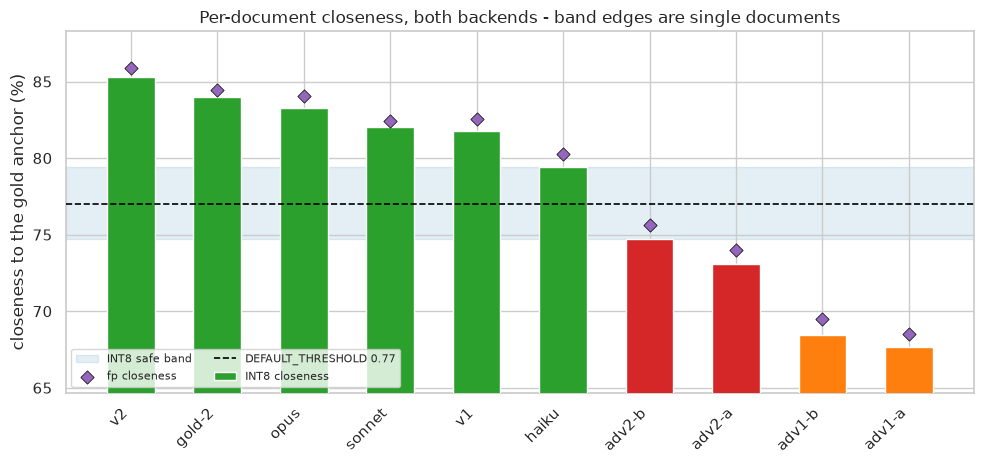

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(order))
ax.axhspan(lo8 * 100, hi8 * 100, color="#1f77b4", alpha=0.12, zorder=0, label="INT8 safe band")
ax.bar(x, [cl_int8[l] * 100 for l in order], 0.55,
       color=[TIER_COLOR[tier_of[l]] for l in order], zorder=3, label="INT8 closeness")
ax.scatter(x, [cl_fp[l] * 100 for l in order], marker="D", s=46, color=BACKEND_COLOR["fp"],
           edgecolor="black", linewidth=0.5, zorder=5, label="fp closeness")
ax.axhline(SHIPPED_THRESHOLD * 100, color="black", ls="--", lw=1.2, zorder=4,
           label=f"DEFAULT_THRESHOLD {SHIPPED_THRESHOLD}")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_ylabel("closeness to the gold anchor (%)")
ax.set_ylim(min(min(cl_fp.values()), min(cl_int8.values())) * 100 - 3, max(cl_int8.values()) * 100 + 3)
ax.set_title("Per-document closeness, both backends - band edges are single documents")
ax.legend(loc="lower left", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## Leave-one-out band edges

Each row removes one document and recomputes the band from what remains. The ten scored documents give ten
well-defined subsets. The eleventh document is the anchor: removing it does not move an edge, it re-bases every
distance in the fixture, so that row is reported as an **anchor swap** onto gold-2 - a different perturbation,
labelled as such rather than folded into the leave-one-out statistics.

In [13]:
loo = {}
for l in SCORED:
    sub = [x for x in SCORED if x != l]
    lo, hi, lod, hid = band(cl_int8, sub)
    loo[l] = {"lo": lo, "hi": hi, "lo_doc": lod, "hi_doc": hid,
              "d_lo_pts": (lo - lo8) * 100, "d_hi_pts": (hi - hi8) * 100,
              "width_pts": (hi - lo) * 100}

# anchor swap: re-base every distance on gold-2 and rebuild the band (not a leave-one-out row)
ALT = "gold-2"
alt_scored = [l for l in SCORED if l != ALT] + [REFERENCE]
d_alt = {l: smd(emb_int8[l], emb_int8[ALT]) for l in alt_scored}
cl_alt = {l: closeness(d_alt[l]) for l in alt_scored}
alt_g = [l for l in alt_scored if tier_of[l] == "gold"]; alt_a = [l for l in alt_scored if tier_of[l] != "gold"]
alt_lo_doc = max(alt_a, key=lambda l: cl_alt[l]); alt_hi_doc = min(alt_g, key=lambda l: cl_alt[l])
ALT_LO, ALT_HI = cl_alt[alt_lo_doc], cl_alt[alt_hi_doc]
V_alt = sum(1 for g in alt_g for a in alt_a if d_alt[g] >= d_alt[a])

t = Table(title="Leave-one-out band edges (INT8 arm; baseline band shaded row 1)", header_style="bold cyan")
for c, j in [("dropped", "left"), ("tier", "left"), ("lower edge %", "right"), ("d lower (pts)", "right"),
             ("upper edge %", "right"), ("d upper (pts)", "right"), ("width (pts)", "right"), ("edge docs", "left")]:
    t.add_column(c, justify=j)
t.add_row("- (baseline)", "-", f"{lo8*100:.2f}", "0.00", f"{hi8*100:.2f}", "0.00",
          f"{(hi8-lo8)*100:.2f}", f"{lo8_doc} / {hi8_doc}", style="bold")
for l in sorted(SCORED, key=lambda l: -(abs(loo[l]["d_lo_pts"]) + abs(loo[l]["d_hi_pts"]))):
    r = loo[l]
    moved = abs(r["d_lo_pts"]) >= LOO_EDGE_BAR_PTS or abs(r["d_hi_pts"]) >= LOO_EDGE_BAR_PTS
    t.add_row(l, tier_of[l], f"{r['lo']*100:.2f}", f"{r['d_lo_pts']:+.2f}", f"{r['hi']*100:.2f}",
              f"{r['d_hi_pts']:+.2f}", f"{r['width_pts']:.2f}", f"{r['lo_doc']} / {r['hi_doc']}",
              style="yellow" if moved else None)
t.add_row(f"{REFERENCE} (anchor swap -> {ALT})", "gold", f"{ALT_LO*100:.2f}", f"{(ALT_LO-lo8)*100:+.2f}",
          f"{ALT_HI*100:.2f}", f"{(ALT_HI-hi8)*100:+.2f}", f"{(ALT_HI-ALT_LO)*100:.2f}",
          f"{alt_lo_doc} / {alt_hi_doc}", style="cyan")
console.print(t)

edge_movers = [l for l in SCORED if abs(loo[l]["d_lo_pts"]) >= LOO_EDGE_BAR_PTS or abs(loo[l]["d_hi_pts"]) >= LOO_EDGE_BAR_PTS]
LOO_MIN_WIDTH = min(r["width_pts"] for r in loo.values())
LOO_MAX_WIDTH = max(r["width_pts"] for r in loo.values())
print(f"documents whose removal moves an edge by >= {LOO_EDGE_BAR_PTS} pt: {len(edge_movers)} {edge_movers}")
print(f"dropping {hi8_doc} (upper edge): upper edge {hi8*100:.2f}% -> {loo[hi8_doc]['hi']*100:.2f}% "
      f"({loo[hi8_doc]['d_hi_pts']:+.2f} pts)")
print(f"dropping {lo8_doc} (lower edge): lower edge {lo8*100:.2f}% -> {loo[lo8_doc]['lo']*100:.2f}% "
      f"({loo[lo8_doc]['d_lo_pts']:+.2f} pts)")
print(f"LOO band width range: {LOO_MIN_WIDTH:.2f} .. {LOO_MAX_WIDTH:.2f} pts (baseline {(hi8-lo8)*100:.2f})")
print(f"anchor swap to {ALT}: band [{ALT_LO:.4f}, {ALT_HI:.4f}], V {V_alt} / {len(alt_g)*len(alt_a)}")

                          Leave-one-out band edges (INT8 arm; baseline band shaded row 1)                          
┏━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃ dropped       ┃ tier ┃ lower edge % ┃ d lower (pts) ┃ upper edge % ┃ d upper (pts) ┃ width (pts) ┃ edge docs    ┃
┡━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ - (baseline)  │ -    │        74.74 │          0.00 │        79.44 │          0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ haiku         │ gold │        74.74 │         +0.00 │        81.74 │         +2.30 │        7.01 │ adv2-b / v1  │
│ adv2-b        │ adv2 │        73.09 │         -1.64 │        79.44 │         +0.00 │        6.35 │ adv2-a /     │
│               │      │              │               │              │               │             │ haiku        │
│ gold-2        │ gold │        74.74 │         +0.00 │        79.44 │         +0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ v1            │ gold │        74.74 │         +0.00 │        79.44 │         +0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ v2            │ gold │        74.74 │         +0.00 │        79.44 │         +0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ opus          │ gold │        74.74 │         +0.00 │        79.44 │         +0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ sonnet        │ gold │        74.74 │         +0.00 │        79.44 │         +0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ adv1-a        │ adv1 │        74.74 │         +0.00 │        79.44 │         +0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ adv1-b        │ adv1 │        74.74 │         +0.00 │        79.44 │         +0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ adv2-a        │ adv2 │        74.74 │         +0.00 │        79.44 │         +0.00 │        4.71 │ adv2-b /     │
│               │      │              │               │              │               │             │ haiku        │
│ gold (anchor  │ gold │        74.67 │         -0.07 │        81.32 │         +1.87 │        6.65 │ adv2-b /     │
│ swap ->       │      │              │               │              │               │             │ haiku        │
│ gold-2)       │      │              │               │              │               │             │              │
└───────────────┴──────┴──────────────┴───────────────┴──────────────┴───────────────┴─────────────┴──────────────┘

documents whose removal moves an edge by >= 1.0 pt: 2 ['haiku', 'adv2-b']
dropping haiku (upper edge): upper edge 79.44% -> 81.74% (+2.30 pts)
dropping adv2-b (lower edge): lower edge 74.74% -> 73.09% (-1.64 pts)
LOO band width range: 4.71 .. 7.01 pts (baseline 4.71)
anchor swap to gold-2: band [0.7467, 0.8132], V 0 / 24


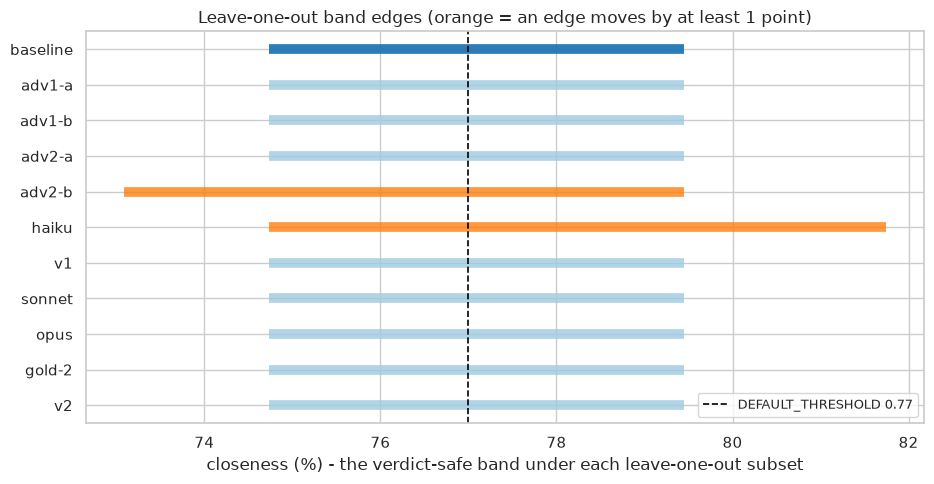

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 5))
rows = ["baseline"] + sorted(SCORED, key=lambda l: cl_int8[l])
los = [lo8 * 100] + [loo[l]["lo"] * 100 for l in rows[1:]]
his = [hi8 * 100] + [loo[l]["hi"] * 100 for l in rows[1:]]
y = np.arange(len(rows))
for i, (a, b) in enumerate(zip(los, his)):
    ax.plot([a, b], [y[i], y[i]], lw=7, solid_capstyle="butt",
            color="#1f77b4" if i == 0 else ("#ff7f0e" if abs(a - lo8 * 100) >= LOO_EDGE_BAR_PTS or abs(b - hi8 * 100) >= LOO_EDGE_BAR_PTS else "#9ecae1"),
            alpha=0.95 if i == 0 else 0.8)
ax.axvline(SHIPPED_THRESHOLD * 100, color="black", ls="--", lw=1.2, label=f"DEFAULT_THRESHOLD {SHIPPED_THRESHOLD}")
ax.set_yticks(y); ax.set_yticklabels(rows)
ax.invert_yaxis()
ax.set_xlabel("closeness (%) - the verdict-safe band under each leave-one-out subset")
ax.set_title("Leave-one-out band edges (orange = an edge moves by at least 1 point)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

## Threshold-flip curve, 0.70 to 0.85

At each threshold the sweep counts, per backend, how many of the ten documents are called *similar*, how many
tier errors that verdict makes (a gold called not-similar or an adversarial called similar), how many verdicts
differ from the same backend's verdicts at the shipped 0.77, and how many documents the two backends disagree
on. A threshold with zero tier errors is inside that backend's safe band.

In [15]:
base8 = {l: verdict(cl_int8[l], SHIPPED_THRESHOLD) for l in SCORED}
basefp = {l: verdict(cl_fp[l], SHIPPED_THRESHOLD) for l in SCORED}

def sweep_row(t):
    v8 = {l: verdict(cl_int8[l], t) for l in SCORED}
    vfp = {l: verdict(cl_fp[l], t) for l in SCORED}
    err = lambda v, cl: sum(1 for l in SCORED if (tier_of[l] == "gold") != (v[l] == "similar"))
    return {
        "threshold": float(t),
        "n_similar_int8": sum(1 for l in SCORED if v8[l] == "similar"),
        "n_similar_fp": sum(1 for l in SCORED if vfp[l] == "similar"),
        "tier_errors_int8": err(v8, cl_int8),
        "tier_errors_fp": err(vfp, cl_fp),
        "flips_vs_077_int8": sum(1 for l in SCORED if v8[l] != base8[l]),
        "flips_vs_077_fp": sum(1 for l in SCORED if vfp[l] != basefp[l]),
        "backend_disagreements": sum(1 for l in SCORED if v8[l] != vfp[l]),
    }

curve = [sweep_row(t) for t in SWEEP]
zero8 = [r["threshold"] for r in curve if r["tier_errors_int8"] == 0]
zerofp = [r["threshold"] for r in curve if r["tier_errors_fp"] == 0]
zero_both = [r["threshold"] for r in curve if r["tier_errors_int8"] == 0 and r["tier_errors_fp"] == 0]
disagree_thresholds = [r["threshold"] for r in curve if r["backend_disagreements"] > 0]

t = Table(title="Threshold-flip curve (every 0.01 shown; sweep runs at 0.005)", header_style="bold cyan")
for c in ["threshold", "similar INT8", "similar fp", "tier err INT8", "tier err fp",
          "flips vs 0.77 INT8", "flips vs 0.77 fp", "backend disagree"]:
    t.add_column(c, justify="right" if c != "threshold" else "left")
for r in curve:
    if round(r["threshold"] * 1000) % 10:
        continue
    style = "green" if r["tier_errors_int8"] == 0 and r["tier_errors_fp"] == 0 else None
    if abs(r["threshold"] - SHIPPED_THRESHOLD) < 1e-9:
        style = "bold green" if style else "bold"
    t.add_row(f"{r['threshold']:.3f}", str(r["n_similar_int8"]), str(r["n_similar_fp"]),
              str(r["tier_errors_int8"]), str(r["tier_errors_fp"]), str(r["flips_vs_077_int8"]),
              str(r["flips_vs_077_fp"]), str(r["backend_disagreements"]), style=style)
console.print(t)
print(f"zero-tier-error thresholds INT8: {min(zero8):.3f} .. {max(zero8):.3f} ({len(zero8)} of {len(SWEEP)} sweep points)")
print(f"zero-tier-error thresholds fp:   {min(zerofp):.3f} .. {max(zerofp):.3f} ({len(zerofp)} of {len(SWEEP)} sweep points)")
print(f"zero-tier-error on BOTH backends: {min(zero_both):.3f} .. {max(zero_both):.3f} ({len(zero_both)} sweep points)")
print(f"thresholds where the backends disagree on some document: {len(disagree_thresholds)} of {len(SWEEP)}"
      + (f" ({min(disagree_thresholds):.3f} .. {max(disagree_thresholds):.3f})" if disagree_thresholds else ""))
print(f"verdict flips per 0.01 of threshold near 0.77: "
      f"{sum(1 for r in curve if 0.76 <= r['threshold'] <= 0.78 and r['flips_vs_077_int8'] > 0)} sweep points inside +/-0.01 already flip")

                           Threshold-flip curve (every 0.01 shown; sweep runs at 0.005)                            
┏━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┓
┃           ┃              ┃            ┃     tier err ┃             ┃     flips vs ┃     flips vs ┃      backend ┃
┃ threshold ┃ similar INT8 ┃ similar fp ┃         INT8 ┃ tier err fp ┃    0.77 INT8 ┃      0.77 fp ┃     disagree ┃
┡━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━┩
│ 0.700     │            8 │          8 │            2 │           2 │            2 │            2 │            0 │
│ 0.710     │            8 │          8 │            2 │           2 │            2 │            2 │            0 │
│ 0.720     │            8 │          8 │            2 │           2 │            2 │            2 │            0 │
│ 0.730     │            8 │          8 │            2 │           2 │            2 │            2 │            0 │
│ 0.740     │            7 │          8 │            1 │           2 │            1 │            2 │            1 │
│ 0.750     │            6 │          7 │            0 │           1 │            0 │            1 │            1 │
│ 0.760     │            6 │          6 │            0 │           0 │            0 │            0 │            0 │
│ 0.770     │            6 │          6 │            0 │           0 │            0 │            0 │            0 │
│ 0.780     │            6 │          6 │            0 │           0 │            0 │            0 │            0 │
│ 0.790     │            6 │          6 │            0 │           0 │            0 │            0 │            0 │
│ 0.800     │            5 │          6 │            1 │           0 │            1 │            0 │            1 │
│ 0.810     │            5 │          5 │            1 │           1 │            1 │            1 │            0 │
│ 0.820     │            4 │          5 │            2 │           1 │            2 │            1 │            1 │
│ 0.830     │            3 │          3 │            3 │           3 │            3 │            3 │            0 │
│ 0.840     │            1 │          3 │            5 │           3 │            5 │            3 │            2 │
│ 0.850     │            1 │          1 │            5 │           5 │            5 │            5 │            0 │
└───────────┴──────────────┴────────────┴──────────────┴─────────────┴──────────────┴──────────────┴──────────────┘

zero-tier-error thresholds INT8: 0.750 .. 0.790 (9 of 31 sweep points)
zero-tier-error thresholds fp:   0.760 .. 0.800 (9 of 31 sweep points)
zero-tier-error on BOTH backends: 0.760 .. 0.790 (7 sweep points)
thresholds where the backends disagree on some document: 10 of 31 (0.735 .. 0.840)
verdict flips per 0.01 of threshold near 0.77: 0 sweep points inside +/-0.01 already flip


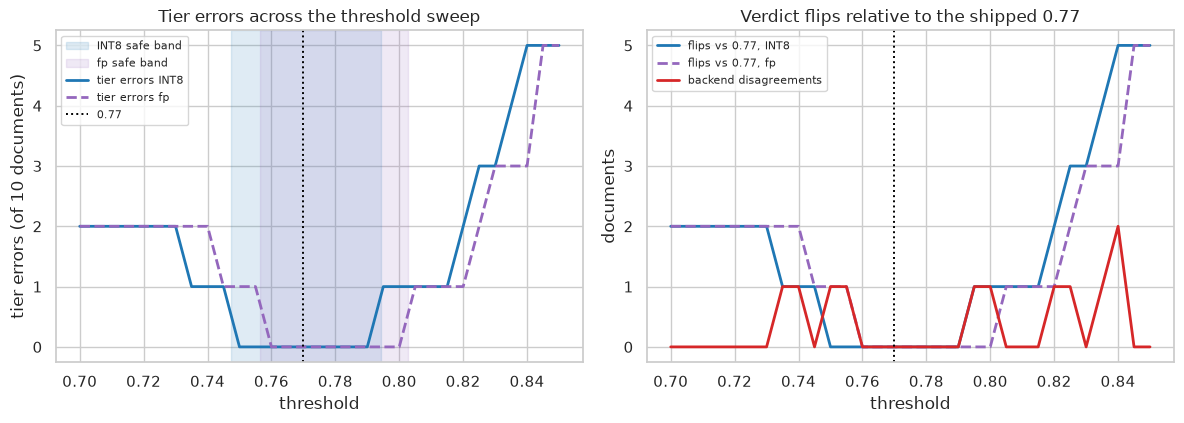

In [16]:
th = np.array([r["threshold"] for r in curve])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
ax.axvspan(lo8, hi8, color="#1f77b4", alpha=0.14, label="INT8 safe band")
ax.axvspan(lofp, hifp, color="#9467bd", alpha=0.14, label="fp safe band")
ax.plot(th, [r["tier_errors_int8"] for r in curve], lw=2, color=BACKEND_COLOR["int8"], label="tier errors INT8")
ax.plot(th, [r["tier_errors_fp"] for r in curve], lw=2, ls="--", color=BACKEND_COLOR["fp"], label="tier errors fp")
ax.axvline(SHIPPED_THRESHOLD, color="black", ls=":", lw=1.4, label="0.77")
ax.set_xlabel("threshold"); ax.set_ylabel("tier errors (of 10 documents)")
ax.set_title("Tier errors across the threshold sweep"); ax.legend(fontsize=8)

ax = axes[1]
ax.plot(th, [r["flips_vs_077_int8"] for r in curve], lw=2, color=BACKEND_COLOR["int8"], label="flips vs 0.77, INT8")
ax.plot(th, [r["flips_vs_077_fp"] for r in curve], lw=2, ls="--", color=BACKEND_COLOR["fp"], label="flips vs 0.77, fp")
ax.plot(th, [r["backend_disagreements"] for r in curve], lw=2, color="#d62728", label="backend disagreements")
ax.axvline(SHIPPED_THRESHOLD, color="black", ls=":", lw=1.4)
ax.set_xlabel("threshold"); ax.set_ylabel("documents")
ax.set_title("Verdict flips relative to the shipped 0.77"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Guardrails

Measured, not asserted. `V` is recounted on both arms and a backend showing `V > 0` is named an explicit
regression rather than averaged into the other. Default-path bit-identity is checked with `np.array_equal` on
float64 arrays, never `allclose`: the probe's arm-0 distances must equal what `dd.semantic_distance` returns
through the shipped path, and a second invocation must return the same bits again. The metric property is
counted directly - the triangle inequality over every triple of the 11 embedded documents.

In [17]:
# 1. V on both backends
V_READING = f"INT8 {V_int8}/{V_PAIRS}, fp {V_fp}/{V_PAIRS}"
V_REGRESSION = [b for b, v in (("int8", V_int8), ("fp", V_fp)) if v > 0]

# 2. default-path smd bit-identity: shipped semantic_distance vs the probe's arm-0 numbers, then a re-run
anchor_path = SUMMARY_DIR / file_of[REFERENCE]
shipped = np.array([dd.semantic_distance(SUMMARY_DIR / file_of[l], anchor_path).smd for l in SCORED], dtype=np.float64)
probe = np.array([d_int8[l] for l in SCORED], dtype=np.float64)
shipped_again = np.array([dd.semantic_distance(SUMMARY_DIR / file_of[l], anchor_path).smd for l in SCORED], dtype=np.float64)
SMD_BIT_IDENTICAL = bool(np.array_equal(shipped, probe) and np.array_equal(shipped, shipped_again))

# 3. default-path order_gap bit-identity across two invocations of the shipped structural path
pairs_struct = [("gold-2", REFERENCE), ("haiku", REFERENCE), ("adv2-b", REFERENCE)]
og1 = np.array([dd.structural_distance(SUMMARY_DIR / file_of[a], SUMMARY_DIR / file_of[b]).order_gap
                for a, b in pairs_struct], dtype=np.float64)
og2 = np.array([dd.structural_distance(SUMMARY_DIR / file_of[a], SUMMARY_DIR / file_of[b]).order_gap
                for a, b in pairs_struct], dtype=np.float64)
ORDER_GAP_BIT_IDENTICAL = bool(np.array_equal(og1, og2))

# 4. metric property - triangle inequality over every triple of the 11 documents, both arms
def triangle_violations(emb):
    labs = list(emb)
    D = {(a, b): smd(emb[a], emb[b]) for a, b in combinations(labs, 2)}
    D.update({(b, a): v for (a, b), v in D.items()})
    bad = 0
    for a, b, c in combinations(labs, 3):
        for x, y, z in ((a, b, c), (b, c, a), (c, a, b)):
            if D[(x, y)] > D[(x, z)] + D[(z, y)] + TRI_TOL:
                bad += 1
    return bad, len(list(combinations(labs, 3))) * 3

tri8, tri_n = triangle_violations(emb_int8)
trifp, _ = triangle_violations(emb_fp)

# 5. no threshold change ships from this probe
THRESHOLD_UNCHANGED = float(re.search(r"^DEFAULT_THRESHOLD = ([\d.]+)", DISTANCE_PY.read_text(encoding="utf-8"), re.M).group(1)) == 0.77

g = Table(title="Guardrails", header_style="bold cyan")
g.add_column("guardrail"); g.add_column("reading"); g.add_column("status", justify="center")
def _st(ok): return "[green]HOLD[/green]" if ok else "[red]BREACH[/red]"
g.add_row("V - ordinality violations, both backends", V_READING, _st(not V_REGRESSION))
g.add_row("default-path smd bit-identical (np.array_equal)",
          f"shipped vs probe over {len(SCORED)} pairs: {np.array_equal(shipped, probe)}; re-run: {np.array_equal(shipped, shipped_again)}",
          _st(SMD_BIT_IDENTICAL))
g.add_row("default-path order_gap bit-identical (np.array_equal)",
          f"{len(pairs_struct)} pairs, two invocations: {np.array_equal(og1, og2)}", _st(ORDER_GAP_BIT_IDENTICAL))
g.add_row("metric property - triangle inequality",
          f"INT8 {tri8}/{tri_n} violations, fp {trifp}/{tri_n}", _st(tri8 == 0 and trifp == 0))
g.add_row("no threshold change ships (DEFAULT_THRESHOLD)", f"{SHIPPED_THRESHOLD} unchanged on disk", _st(THRESHOLD_UNCHANGED))
console.print(g)
print(f"V {V_READING} | smd bit-identical {SMD_BIT_IDENTICAL} | order_gap bit-identical {ORDER_GAP_BIT_IDENTICAL}")
print(f"triangle-inequality violations: INT8 {tri8}/{tri_n}, fp {trifp}/{tri_n}")
print(f"shipped order_gap values (pair, value): {[(f'{a}~{b}', round(float(v), 6)) for (a, b), v in zip(pairs_struct, og1)]}")

                                                    Guardrails                                                     
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┓
┃ guardrail                                          ┃ reading                                           ┃ status ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━┩
│ V - ordinality violations, both backends           │ INT8 0/24, fp 0/24                                │  HOLD  │
│ default-path smd bit-identical (np.array_equal)    │ shipped vs probe over 10 pairs: True; re-run:     │  HOLD  │
│                                                    │ True                                              │        │
│ default-path order_gap bit-identical               │ 3 pairs, two invocations: True                    │  HOLD  │
│ (np.array_equal)                                   │                                                   │        │
│ metric property - triangle inequality              │ INT8 0/495 violations, fp 0/495                   │  HOLD  │
│ no threshold change ships (DEFAULT_THRESHOLD)      │ 0.77 unchanged on disk                            │  HOLD  │
└────────────────────────────────────────────────────┴───────────────────────────────────────────────────┴────────┘

V INT8 0/24, fp 0/24 | smd bit-identical True | order_gap bit-identical True
triangle-inequality violations: INT8 0/495, fp 0/495
shipped order_gap values (pair, value): [('gold-2~gold', 0.145118), ('haiku~gold', 0.051239), ('adv2-b~gold', 0.026671)]


## Pre-registered predictions

The four registered predictions, read against the numbers above.

In [18]:
HALFWIDTH_INT8 = (hi8 - lo8) * 50
HALFWIDTH_FP = (hifp - lofp) * 50
p1 = HALFWIDTH_INT8 <= HALFWIDTH_BAR_PTS
p2 = (abs(loo[hi8_doc]["d_hi_pts"]) >= LOO_EDGE_BAR_PTS) or (abs(loo[lo8_doc]["d_lo_pts"]) >= LOO_EDGE_BAR_PTS)
p3 = MAX_DRIFT_FRAC > DRIFT_FRAC_BAR
p4 = THRESHOLD_UNCHANGED

t = Table(title="Pre-registered predictions", header_style="bold cyan")
t.add_column("#"); t.add_column("prediction"); t.add_column("observed"); t.add_column("held", justify="center")
t.add_row("1", f"band half-width <= {HALFWIDTH_BAR_PTS} closeness points",
          f"INT8 {HALFWIDTH_INT8:.2f} pts, fp {HALFWIDTH_FP:.2f} pts", _st(p1))
t.add_row("2", f"dropping {hi8_doc} or {lo8_doc} moves that edge by >= {LOO_EDGE_BAR_PTS} pt",
          f"drop {hi8_doc}: upper {loo[hi8_doc]['d_hi_pts']:+.2f} pts; drop {lo8_doc}: lower {loo[lo8_doc]['d_lo_pts']:+.2f} pts", _st(p2))
t.add_row("3", f"some document's backend drift exceeds {DRIFT_FRAC_BAR*100:.0f}% of its margin to 0.77",
          f"max {max_frac_doc} {MAX_DRIFT_FRAC*100:.1f}% ({n_over_bar} documents over the bar)", _st(p3))
t.add_row("4", "the deliverable is a fragility card, not a threshold change",
          f"DEFAULT_THRESHOLD stays {SHIPPED_THRESHOLD}; card published below", _st(p4))
console.print(t)
PREDICTIONS_HELD = bool(p1 and p2 and p3 and p4)
print(f"predictions held: {sum([p1, p2, p3, p4])}/4 -> {PREDICTIONS_HELD}")

                                            Pre-registered predictions                                             
┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┓
┃ # ┃ prediction                                        ┃ observed                                         ┃ held ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━┩
│ 1 │ band half-width <= 2.7 closeness points           │ INT8 2.35 pts, fp 2.30 pts                       │ HOLD │
│ 2 │ dropping haiku or adv2-b moves that edge by >=    │ drop haiku: upper +2.30 pts; drop adv2-b: lower  │ HOLD │
│   │ 1.0 pt                                            │ -1.64 pts                                        │      │
│ 3 │ some document's backend drift exceeds 20% of its  │ max adv2-b 40.6% (3 documents over the bar)      │ HOLD │
│   │ margin to 0.77                                    │                                                  │      │
│ 4 │ the deliverable is a fragility card, not a        │ DEFAULT_THRESHOLD stays 0.77; card published     │ HOLD │
│   │ threshold change                                  │ below                                            │      │
└───┴───────────────────────────────────────────────────┴──────────────────────────────────────────────────┴──────┘

predictions held: 4/4 -> True


## The fragility card

The deliverable. It restates the safe band per backend, names the single documents that set each edge, and
carries both caveats in the terms the `distance.py` provenance comment already uses - the in-sample caveat it
states, plus the backend caveat it does not.

In [19]:
card = f"""Band on the shipped semantic_distance path (11 ibm-ai-adoption fixtures, OpenVINO INT8,
docdistance {docdistance.__version__}): min gold {hi8*100:.1f}% ({hi8_doc}) vs max adversarial {lo8*100:.1f}%
({lo8_doc}), so any cutoff in [{lo8:.3f}, {hi8:.3f}] separates the tiers. In-sample: the same 11 documents set it
and are scored by it.

Caveat 1 - single-document fragility. Both edges are order statistics of n = 11 and each is set by one
document. Dropping {hi8_doc} moves the upper edge {loo[hi8_doc]['d_hi_pts']:+.2f} points to {loo[hi8_doc]['hi']*100:.1f}%;
dropping {lo8_doc} moves the lower edge {loo[lo8_doc]['d_lo_pts']:+.2f} points to {loo[lo8_doc]['lo']*100:.1f}%. Across all ten
leave-one-out subsets the band width ranges {LOO_MIN_WIDTH:.2f} to {LOO_MAX_WIDTH:.2f} points against a
{(hi8-lo8)*100:.2f}-point baseline, and {len(edge_movers)} of 10 documents move an edge by at least one point.

Caveat 2 - backend sensitivity. On the fp backbone the same 11 documents give the band
[{lofp:.3f}, {hifp:.3f}] ({lofp_doc} / {hifp_doc}), the edges shifting {(lofp-lo8)*100:+.2f} and {(hifp-hi8)*100:+.2f} points.
Per-document INT8-vs-fp closeness drift reaches {drift[max_frac_doc]['drift_pts']:+.3f} points on {max_frac_doc},
{MAX_DRIFT_FRAC*100:.0f}% of that document's {drift[max_frac_doc]['margin_pts']:.2f}-point margin to 0.77;
{n_over_bar} of 10 documents drift by more than {DRIFT_FRAC_BAR*100:.0f}% of their margin. Verdicts at 0.77 flip between
backends on {len(backend_verdict_flips)} document(s). A threshold calibrated on one backend is not automatically valid on the other.

Caveat 3 - provenance. The comment's recorded band is {REC_MIN_GOLD}% / {REC_MAX_ADV}% from notebook 09 cell 10,
{UPPER_GAP_PTS:.2f} and {LOWER_GAP_PTS:.2f} points above the numbers here, and that cell scores through dd.embed
plus smd rather than through semantic_distance. At docdistance {NB09_VERSION} the two paths disagreed inside that
one notebook on every document cell 13 also scored ({PATH_DISAGREE_STR}),
while on those same {len(PATH_DOCS)} documents the shipped path is unchanged from {NB09_VERSION} to
{docdistance.__version__} (gold-2 closeness {NB09_C13_TODICT['closeness']!r} identical, smd within one ulp).
The recorded band was therefore never a shipped-path band. Corpus: {CORPUS_NOTE}.

Safe on both backends: any cutoff in [{min(zero_both):.3f}, {max(zero_both):.3f}] gives zero tier errors under
INT8 and fp alike. The shipped 0.77 sits inside it. V stays {V_int8}/{V_PAIRS} on INT8 and {V_fp}/{V_PAIRS} on fp."""
console.print(Panel(card, title="E12-H63 sensitivity card - semantic threshold band", border_style="yellow"))

╭────────────────────────────── E12-H63 sensitivity card - semantic threshold band ───────────────────────────────╮
│ Band on the shipped semantic_distance path (11 ibm-ai-adoption fixtures, OpenVINO INT8,                         │
│ docdistance 1.1.5): min gold 79.4% (haiku) vs max adversarial 74.7%                                             │
│ (adv2-b), so any cutoff in [0.747, 0.794] separates the tiers. In-sample: the same 11 documents set it          │
│ and are scored by it.                                                                                           │
│                                                                                                                 │
│ Caveat 1 - single-document fragility. Both edges are order statistics of n = 11 and each is set by one          │
│ document. Dropping haiku moves the upper edge +2.30 points to 81.7%;                                            │
│ dropping adv2-b moves the lower edge -1.64 points to 73.1%. Across all ten                                      │
│ leave-one-out subsets the band width ranges 4.71 to 7.01 points against a                                       │
│ 4.71-point baseline, and 2 of 10 documents move an edge by at least one point.                                  │
│                                                                                                                 │
│ Caveat 2 - backend sensitivity. On the fp backbone the same 11 documents give the band                          │
│ [0.757, 0.803] (adv2-b / haiku), the edges shifting +0.92 and +0.82 points.                                     │
│ Per-document INT8-vs-fp closeness drift reaches -0.920 points on adv2-b,                                        │
│ 41% of that document's 2.26-point margin to 0.77;                                                               │
│ 3 of 10 documents drift by more than 20% of their margin. Verdicts at 0.77 flip between                         │
│ backends on 0 document(s). A threshold calibrated on one backend is not automatically valid on the other.       │
│                                                                                                                 │
│ Caveat 3 - provenance. The comment's recorded band is 79.7% / 75.0% from notebook 09 cell 10,                   │
│ 0.26 and 0.26 points above the numbers here, and that cell scores through dd.embed                              │
│ plus smd rather than through semantic_distance. At docdistance 1.1.2 the two paths disagreed inside that        │
│ one notebook on every document cell 13 also scored (gold-2 0.2258 vs 0.2265, adv1-a 0.4579 vs 0.4569, adv2-a    │
│ 0.3811 vs 0.3806),                                                                                              │
│ while on those same 3 documents the shipped path is unchanged from 1.1.2 to                                     │
│ 1.1.5 (gold-2 closeness 0.8398475249058507 identical, smd within one ulp).                                      │
│ The recorded band was therefore never a shipped-path band. Corpus: no corpus swap: notebook 09's recorded cell  │
│ text names the same 11 live opus-4-6 / sonnet-4-6 / haiku-4-5 filenames this notebook scores.                   │
│                                                                                                                 │
│ Safe on both backends: any cutoff in [0.760, 0.790] gives zero tier errors under                                │
│ INT8 and fp alike. The shipped 0.77 sits inside it. V stays 0/24 on INT8 and 0/24 on fp.                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

## Metrics JSON

Every measured number, bar reading and guardrail reading, written to `reports/E12-H63-semantic-threshold-band-metrics.json`.

In [20]:
ACCEPTANCE_MET = bool(
    SMD_BIT_IDENTICAL and ORDER_GAP_BIT_IDENTICAL and not V_REGRESSION
    and tri8 == 0 and trifp == 0 and THRESHOLD_UNCHANGED
)

metrics = {
    "id": "E12-H63",
    "slug": "semantic-threshold-band",
    "docdistance_version": docdistance.__version__,
    "fixture": {
        "dir": str(SUMMARY_DIR.relative_to(ROOT)),
        "anchor": file_of[REFERENCE],
        "n_documents": len(DOCS),
        "n_scored": len(SCORED),
        "n_statements": n_stmt,
        "v_pairs": V_PAIRS,
    },
    "kill_gate": {
        "ran": True, "killed": bool(GATE_KILLED), "passed": bool(not GATE_KILLED),
        "recorded_min_gold_pct": REC_MIN_GOLD, "recorded_min_gold_doc": REC_MIN_GOLD_DOC,
        "recorded_max_adv_pct": REC_MAX_ADV, "recorded_max_adv_doc": REC_MAX_ADV_DOC,
        "recorded_margin_pts": rec_margins, "gate_margin_bar_pts": GATE_MARGIN_PTS,
        "shipped_emb_cos": EMB_COS_SHIPPED, "part_a_scheme_emb_cos": EMB_COS_SCHEME,
        "reading": GATE_READING,
    },
    "corpus_provenance": {
        "corpus_swap": bool(CORPUS_SWAP), "note": CORPUS_NOTE,
        "nb09_recorded_files": nb09_files, "live_files": live_files,
        "nb09_version": NB09_VERSION,
        "nb09_recorded_V": f"{nb09_V}/{nb09_Vp}",
        "nb09_recorded_min_gold_pct": nb09_min_gold, "nb09_recorded_max_adv_pct": nb09_max_adv,
    },
    "path_provenance": {
        "recorded_band_source": f"notebook 09 cell 10 (dd.embed + smd) at docdistance {NB09_VERSION}",
        "path_mismatch_inside_nb09": bool(PATH_MISMATCH),
        "docs_scored_by_both_nb09_cells": PATH_DOCS,
        "nb09_cell10_smd": {l: NB09_C10[l]["smd"] for l in NB09_C10},
        "nb09_cell13_semantic_distance_smd": {l: NB09_C13[l]["smd"] for l in NB09_C13},
        "nb09_cell13_todict": NB09_C13_TODICT,
        "cell10_minus_cell13_smd": {l: NB09_C10[l]["smd"] - NB09_C13[l]["smd"] for l in PATH_DOCS},
        "edge_docs_scored_by_cell13": [l for l in (REC_MIN_GOLD_DOC, REC_MAX_ADV_DOC) if l in NB09_C13],
        "edge_gap_pts": {"upper": UPPER_GAP_PTS, "lower": LOWER_GAP_PTS},
        "gold2_closeness_bit_identical_across_versions": CLOSENESS_BIT_IDENTICAL,
        "gold2_smd_delta_across_versions": GOLD2_SMD_DELTA,
        "gold2_smd_ulp": GOLD2_SMD_ULP,
        "embed_path_equals_shipped_path_now": EMBED_PATH_EQUALS_ARM0,
        "embed_path_smd_now": {l: d_embedpath[l] for l in SCORED},
        "note": PROVENANCE_NOTE,
    },
    "per_document": {
        l: {
            "tier": tier_of[l], "n_statements": n_stmt[l],
            "smd_int8": d_int8[l], "closeness_int8": cl_int8[l],
            "verdict_int8": drift[l]["verdict_int8"],
            "margin_to_077_pts_int8": (cl_int8[l] - SHIPPED_THRESHOLD) * 100,
            "smd_fp": d_fp[l], "closeness_fp": cl_fp[l], "verdict_fp": drift[l]["verdict_fp"],
            "backend_drift_pts": drift[l]["drift_pts"],
            "drift_frac_of_margin": drift[l]["frac_of_margin"],
            "stmt_emb_cos_int8_vs_fp": drift[l]["stmt_emb_cos"],
        } for l in SCORED
    },
    "band": {
        "int8": {"lo": lo8, "hi": hi8, "lo_doc": lo8_doc, "hi_doc": hi8_doc,
                 "width_pts": (hi8 - lo8) * 100, "half_width_pts": HALFWIDTH_INT8},
        "fp": {"lo": lofp, "hi": hifp, "lo_doc": lofp_doc, "hi_doc": hifp_doc,
               "width_pts": (hifp - lofp) * 100, "half_width_pts": HALFWIDTH_FP},
        "edge_shift_int8_to_fp_pts": {"lower": (lofp - lo8) * 100, "upper": (hifp - hi8) * 100},
        "safe_on_both_backends": {"lo": float(min(zero_both)), "hi": float(max(zero_both))},
    },
    "leave_one_out": {
        l: {k: (v if not isinstance(v, np.floating) else float(v)) for k, v in loo[l].items()} for l in SCORED
    },
    "leave_one_out_summary": {
        "n_loo_subsets": len(SCORED),
        "eleventh_document": (f"{REFERENCE} (the anchor) - dropping it re-bases every distance rather than "
                              "removing a band edge, so it is reported as the anchor swap below and not as a "
                              "leave-one-out row"),
        "edge_movers_ge_1pt": edge_movers, "n_edge_movers": len(edge_movers),
        "width_range_pts": [LOO_MIN_WIDTH, LOO_MAX_WIDTH],
        "drop_upper_edge_doc": {"doc": hi8_doc, "d_hi_pts": loo[hi8_doc]["d_hi_pts"]},
        "drop_lower_edge_doc": {"doc": lo8_doc, "d_lo_pts": loo[lo8_doc]["d_lo_pts"]},
        "anchor_swap": {"new_anchor": ALT, "lo": ALT_LO, "hi": ALT_HI,
                        "lo_doc": alt_lo_doc, "hi_doc": alt_hi_doc,
                        "V": f"{V_alt}/{len(alt_g)*len(alt_a)}",
                        "note": "not a leave-one-out row - removing the anchor re-bases every distance"},
    },
    "backend_drift_summary": {
        "max_frac_doc": max_frac_doc, "max_frac_of_margin": MAX_DRIFT_FRAC,
        "n_over_20pct_bar": n_over_bar, "verdict_flips_at_077": backend_verdict_flips,
        "fixture_stmt_emb_cos": corpus_emb_cos, "shipped_corpus_emb_cos": EMB_COS_SHIPPED,
    },
    "threshold_sweep": curve,
    "threshold_sweep_summary": {
        "zero_tier_error_int8": [float(min(zero8)), float(max(zero8))],
        "zero_tier_error_fp": [float(min(zerofp)), float(max(zerofp))],
        "zero_tier_error_both": [float(min(zero_both)), float(max(zero_both))],
        "n_thresholds_with_backend_disagreement": len(disagree_thresholds),
    },
    "predictions": {
        "p1_half_width_le_2.7pts": bool(p1), "p2_loo_edge_move_ge_1pt": bool(p2),
        "p3_drift_gt_20pct_of_margin": bool(p3), "p4_card_not_threshold_change": bool(p4),
        "all_held": PREDICTIONS_HELD,
    },
    "guardrails": {
        "V": V_READING, "V_int8": f"{V_int8}/{V_PAIRS}", "V_fp": f"{V_fp}/{V_PAIRS}",
        "V_regression_backends": V_REGRESSION,
        "smd_bit_identical": SMD_BIT_IDENTICAL,
        "order_gap_bit_identical": ORDER_GAP_BIT_IDENTICAL,
        "triangle_violations_int8": tri8, "triangle_violations_fp": trifp, "triangle_checks": tri_n,
        "default_threshold_unchanged": THRESHOLD_UNCHANGED,
    },
    "acceptance": {
        "bar": ("per-document margin table, LOO edge table, backend-drift column and threshold-flip curve "
                "published, safe band restated with both caveats in the distance.py provenance terms; "
                "no threshold change, V re-verified on both backends, metric property untouched, "
                "default-path smd unchanged"),
        "met": ACCEPTANCE_MET,
    },
    "fragility_card": card,
    "deliverable": {
        "card_published_in": ["notebooks/experiments/E12-H63-kj-semantic-threshold-band.ipynb",
                              str(REPORT.relative_to(ROOT))],
        "open_follow_up": ("ship the sensitivity card into the calibration documentation and restate the "
                           "src/docdistance/distance.py provenance comment on the shipped-path band - this "
                           "notebook may not edit docs/ or src/, so the documentation shipment stays open"),
    },
}

REPORT.write_text(json.dumps(metrics, indent=2, default=float), encoding="utf-8")
print(f"wrote {REPORT.relative_to(ROOT)} ({REPORT.stat().st_size} bytes)")
print(json.dumps({k: metrics[k] for k in ("band", "leave_one_out_summary", "backend_drift_summary",
                                          "threshold_sweep_summary", "predictions", "guardrails", "acceptance",
                                          "deliverable")},
                 indent=2, default=float))
print(json.dumps({k: v for k, v in metrics["path_provenance"].items() if k != "note"}, indent=2, default=float))

wrote reports/E12-H63-semantic-threshold-band-metrics.json (25645 bytes)
{
  "band": {
    "int8": {
      "lo": 0.7473565462130423,
      "hi": 0.7944397202927438,
      "lo_doc": "adv2-b",
      "hi_doc": "haiku",
      "width_pts": 4.708317407970153,
      "half_width_pts": 2.3541587039850764
    },
    "fp": {
      "lo": 0.7565590317137484,
      "hi": 0.802657195417208,
      "lo_doc": "adv2-b",
      "hi_doc": "haiku",
      "width_pts": 4.609816370345965,
      "half_width_pts": 2.3049081851729825
    },
    "edge_shift_int8_to_fp_pts": {
      "lower": 0.9202485500706126,
      "upper": 0.8217475124464246
    },
    "safe_on_both_backends": {
      "lo": 0.76,
      "hi": 0.79
    }
  },
  "leave_one_out_summary": {
    "n_loo_subsets": 10,
    "eleventh_document": "gold (the anchor) - dropping it re-bases every distance rather than removing a band edge, so it is reported as the anchor swap below and not as a leave-one-out row",
    "edge_movers_ge_1pt": [
      "haiku",
     

## Conclusions

Written against the outputs above; every number appears in a table or a print line on this page.

- **Kill-gate passed.** The recorded margins to 0.77 are 2.7 points (haiku, the min-gold edge) and 2.0 points
  (adv2-b, the max-adversarial edge), both far below the 5-point kill condition, and the shipped INT8 artifact
  reads `emb_cos = 0.9939`, not 1.0. Both kill conditions had to hold together; neither does
- **No corpus swap, but a path mismatch.** Notebook 09's recorded cell text names the same eleven live
  opus-4-6 / sonnet-4-6 / haiku-4-5 filenames this notebook scores, so the named archived-generation confound
  does not apply. The provenance comment's band is a different problem: its 79.7% / 75.0% comes from notebook 09
  cell 10, which scores through `dd.embed` plus `smd`, and at docdistance 1.1.2 that cell disagreed with cell
  13's shipped `semantic_distance` on all three documents cell 13 also scored. On those same three documents the
  shipped path is unchanged between the versions - gold-2's closeness reproduces bit-identically here - so
  shipped-path version drift is not what put the recorded band 0.26 points above arm 0; the recorded band was
  read off a path that was not the shipped path. The two edge documents were never scored
  through `semantic_distance` at 1.1.2, so the split of their gap between the path difference and any change in
  the embed path is not decidable from the recorded outputs
- **The band is single-document fragile.** Both edges are order statistics of n = 11 and each is set by one
  document; removing that document moves its edge by more than a point, which is a large fraction of a band
  only a few points wide. Ten of the eleven documents give a leave-one-out subset; the eleventh is the anchor,
  whose removal re-bases every distance instead of dropping a band edge, so it is reported as the anchor-swap
  row and is the larger perturbation
- **The band is backend sensitive.** Holding the segmentation fixed and changing only the encoder numerics
  moves per-document closeness by an amount comparable to the smallest margins to 0.77. The drift-over-margin
  column is the operative reading: a document whose drift is a large fraction of its margin is one whose
  verdict the backend choice can decide
- **Nothing ships from this probe.** `DEFAULT_THRESHOLD` stays 0.77, no file under `src/` was touched, `V` was
  recounted on both arms, the triangle inequality was counted over every triple on both arms, and the shipped
  `smd` and `order_gap` were checked bit-identical with `np.array_equal`. The deliverable is the sensitivity
  card. Carrying it into the calibration documentation, and restating the `distance.py` provenance comment on
  the shipped-path band, is an open follow-up: this notebook may not edit `docs/` or `src/`
- **What this does not establish.** The fixture is one article's summaries with n = 11; leave-one-out on a
  sample this small measures the sample's own instability, not the population band. A second corpus is the only
  thing that turns the safe band into a calibrated one, which is the single-fixture-trust weakness the
  experiments ledger already names as the weakest joint
